1. 安装/导入必要库

In [1]:
# =====================================
# AI+地学课程设计版
# 南太行生态修复时空分析
# =====================================

import os
import re
import rasterio
import warnings
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from tqdm import tqdm

from scipy.stats import skew,kurtosis

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

import shap

warnings.filterwarnings("ignore")

plt.rcParams['font.sans-serif']=['Microsoft YaHei']
plt.rcParams['axes.unicode_minus']=False

sns.set_theme(
    style="white",
    font="Microsoft YaHei"
)

学习用\数据挖掘\text\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2. 定义读取所有年份数据的函数

In [2]:
import os
import re
import rasterio
import numpy as np
import pandas as pd
from tqdm import tqdm


def get_sample_points_from_first_tif(folder, sample_size=8000):
    """从第一个tif中获取统一的采样点坐标"""
    files = [f for f in os.listdir(folder) if f.lower().endswith(".tif")]
    if len(files) == 0:
        raise ValueError(f"{folder} 中没有找到tif文件")
    
    # 取第一个tif作为参考
    first_tif = files[0]
    path = os.path.join(folder, first_tif)
    
    with rasterio.open(path) as src:
        arr = src.read(1, masked=True)
        valid = np.where(~arr.mask)
        total = len(valid[0])
        
        if total == 0:
            raise ValueError("第一个tif没有有效数据")
        
        n = min(sample_size, total)
        idx = np.random.choice(total, n, replace=False)
        
        rows = valid[0][idx]
        cols = valid[1][idx]
        
        return rows, cols, src


def read_raster_samples_unified(folder, var_name, sample_rows, sample_cols, ref_src):
    """使用统一采样点读取所有年份数据"""
    all_df = []
    files = os.listdir(folder)
    
    print(f"\n正在扫描 {folder}")
    print(f"发现文件数：{len(files)}")

    for tif in tqdm(files):
        if not tif.lower().endswith(".tif"):
            continue

        years = re.findall(r"\d{4}", tif)
        if len(years) == 0:
            print(f"跳过无法识别年份文件: {tif}")
            continue

        year = int(years[-1])
        path = os.path.join(folder, tif)

        try:
            with rasterio.open(path) as src:
                arr = src.read(1, masked=True)
                values = arr[sample_rows, sample_cols]
                xs, ys = ref_src.xy(sample_rows, sample_cols)

                temp = pd.DataFrame({
                    "lon": xs,
                    "lat": ys,
                    var_name: values,
                    "year": year
                })
                all_df.append(temp)

        except Exception as e:
            print(f"读取失败 {tif}")
            print(e)

    if len(all_df) == 0:
        raise ValueError(f"{folder} 中没有成功读取任何tif")

    return pd.concat(all_df, ignore_index=True)

3. 设定路径并读取数据（2013–2024）

In [3]:
BASE_PATH = r"dasai\南太行数据"

PM25_PATH = os.path.join(
    BASE_PATH,
    "pm2.5"
)

HABITAT_PATH = os.path.join(
    BASE_PATH,
    "生境质量"
)

FVC_PATH = os.path.join(
    BASE_PATH,
    "FVC"
)

OUT_DIR = os.path.join(
    BASE_PATH,
    "AI分析结果"
)

os.makedirs(
    OUT_DIR,
    exist_ok=True
)

print("路径已定义：")
print(f"PM25_PATH: {PM25_PATH}")
print(f"HABITAT_PATH: {HABITAT_PATH}")
print(f"FVC_PATH: {FVC_PATH}")
print(f"输出目录: {OUT_DIR}")

路径已定义：
PM25_PATH: dasai\南太行数据\pm2.5
HABITAT_PATH: dasai\南太行数据\生境质量
FVC_PATH: dasai\南太行数据\FVC
输出目录: dasai\南太行数据\AI分析结果


4. 按年份和位置合并三个变量

In [4]:
# ========== 修复：使用统一采样点，确保三个变量坐标一致 ==========
# 1. 先从第一个文件夹获取统一的采样点
sample_rows, sample_cols, ref_src = get_sample_points_from_first_tif(PM25_PATH, sample_size=8000)

# 2. 使用相同的采样点读取三个变量
pm25_df = read_raster_samples_unified(PM25_PATH, "pm25", sample_rows, sample_cols, ref_src)
habitat_df = read_raster_samples_unified(HABITAT_PATH, "habitat", sample_rows, sample_cols, ref_src)
fvc_df = read_raster_samples_unified(FVC_PATH, "fvc", sample_rows, sample_cols, ref_src)

print(pm25_df.head())
print(pm25_df.shape)
print(habitat_df.head())
print(habitat_df.shape)
print(fvc_df.head())
print(fvc_df.shape)


正在扫描 dasai\南太行数据\pm2.5
发现文件数：6


100%|██████████| 6/6 [00:03<00:00,  1.70it/s]



正在扫描 dasai\南太行数据\生境质量
发现文件数：6


100%|██████████| 6/6 [00:03<00:00,  1.57it/s]



正在扫描 dasai\南太行数据\FVC
发现文件数：6


100%|██████████| 6/6 [00:03<00:00,  1.74it/s]

             lon           lat       pm25  year
0  642610.216954  3.765827e+06  56.100002  2019
1  730300.216954  3.757517e+06  61.400002  2019
2  640960.216954  3.761387e+06  56.100002  2019
3  812770.216954  3.834197e+06  60.700001  2019
4  782140.216954  3.813497e+06  58.700001  2019
(48000, 4)
             lon           lat   habitat  year
0  642610.216954  3.765827e+06  0.368724  2019
1  730300.216954  3.757517e+06  0.357503  2019
2  640960.216954  3.761387e+06  0.499943  2019
3  812770.216954  3.834197e+06  0.355794  2019
4  782140.216954  3.813497e+06  0.363000  2019
(48000, 4)
             lon           lat       fvc  year
0  642610.216954  3.765827e+06  0.701688  2019
1  730300.216954  3.757517e+06  0.626607  2019
2  640960.216954  3.761387e+06  0.694257  2019
3  812770.216954  3.834197e+06  0.957172  2019
4  782140.216954  3.813497e+06  0.637626  2019
(48000, 4)


In [5]:
# 坐标已经统一，直接合并即可
for d in [pm25_df, habitat_df, fvc_df]:
    d["lon"] = d["lon"].round(4)
    d["lat"] = d["lat"].round(4)

df = pm25_df.merge(
    habitat_df,
    on=["lon", "lat", "year"]
)

df = df.merge(
    fvc_df,
    on=["lon", "lat", "year"]
)

print(f"合并后数据形状: {df.shape}")
print("\n合并后前5行:")
print(df.head())

合并后数据形状: (48000, 6)

合并后前5行:
          lon           lat       pm25  year   habitat       fvc
0  642610.217  3.765827e+06  56.100002  2019  0.368724  0.701688
1  730300.217  3.757517e+06  61.400002  2019  0.357503  0.626607
2  640960.217  3.761387e+06  56.100002  2019  0.499943  0.694257
3  812770.217  3.834197e+06  60.700001  2019  0.355794  0.957172
4  782140.217  3.813497e+06  58.700001  2019  0.363000  0.637626


5. 数据清洗 & 描述性统计

In [6]:
def remove_iqr(df,col):

    q1=df[col].quantile(.25)
    q3=df[col].quantile(.75)

    iqr=q3-q1

    lower=q1-1.5*iqr
    upper=q3+1.5*iqr

    return df[
        (df[col]>=lower)
        &
        (df[col]<=upper)
    ]

for c in [

    "pm25",
    "habitat",
    "fvc"

]:

    df=remove_iqr(df,c)


In [7]:
stats=pd.DataFrame({

    "均值":df[
        ["pm25","habitat","fvc"]
    ].mean(),

    "标准差":df[
        ["pm25","habitat","fvc"]
    ].std(),

    "变异系数":df[
        ["pm25","habitat","fvc"]
    ].std()
    /
    df[
        ["pm25","habitat","fvc"]
    ].mean(),

    "偏度":[
        skew(df[c])
        for c in
        ["pm25","habitat","fvc"]
    ],

    "峰度":[
        kurtosis(df[c])
        for c in
        ["pm25","habitat","fvc"]
    ]

})

stats.to_excel(
    os.path.join(
        OUT_DIR,
        "描述统计.xlsx"
    )
)

6. 时间序列趋势图（美观）

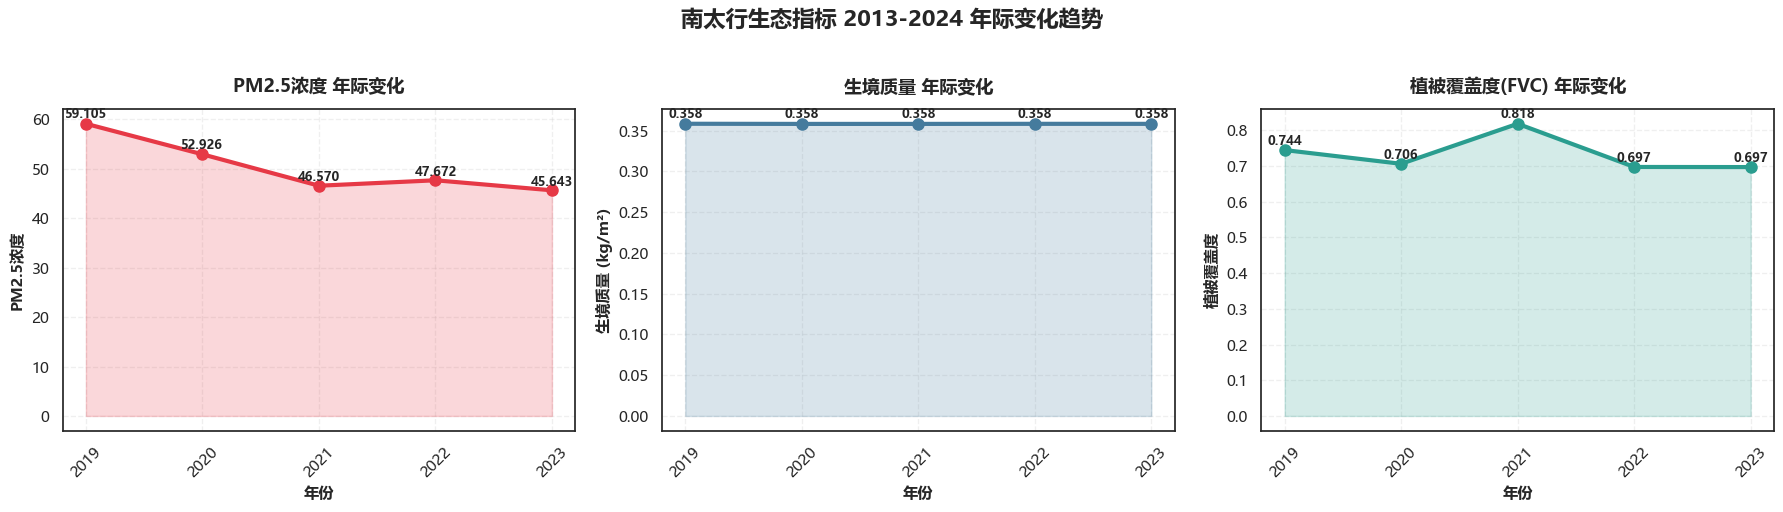

In [8]:
year_mean = df.groupby("year")[["pm25", "habitat", "fvc"]].mean().reset_index()

# 创建3个子图，美观展示
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

colors = ['#E63946', '#457B9D', '#2A9D8F']
titles = ['PM2.5浓度 年际变化', '生境质量 年际变化', '植被覆盖度(FVC) 年际变化']
ylabels = ['PM2.5浓度', '生境质量 (kg/m²)', '植被覆盖度']

for i, col in enumerate(["pm25", "habitat", "fvc"]):
    ax = axes[i]
    
    # 绘制折线
    ax.plot(year_mean["year"], year_mean[col], 
            color=colors[i], linewidth=3, marker='o', markersize=8, zorder=3)
    
    # 填充区域
    ax.fill_between(year_mean["year"], year_mean[col], alpha=0.2, color=colors[i])
    
    # 添加数值标签
    for x, y in zip(year_mean["year"], year_mean[col]):
        ax.text(x, y * 1.02, f'{y:.3f}', ha='center', fontsize=9, fontweight='bold')
    
    ax.set_title(titles[i], fontsize=13, fontweight='bold', pad=12)
    ax.set_xlabel('年份', fontsize=11, fontweight='bold')
    ax.set_ylabel(ylabels[i], fontsize=11, fontweight='bold')
    ax.grid(True, alpha=0.3, linestyle='--')
    ax.set_xticks(year_mean["year"])
    ax.tick_params(axis='x', rotation=45)

plt.suptitle('南太行生态指标 2013-2024 年际变化趋势', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "图1_时间序列趋势.png"), dpi=300, bbox_inches='tight')
plt.show()

7. 相关性热图（含年份）

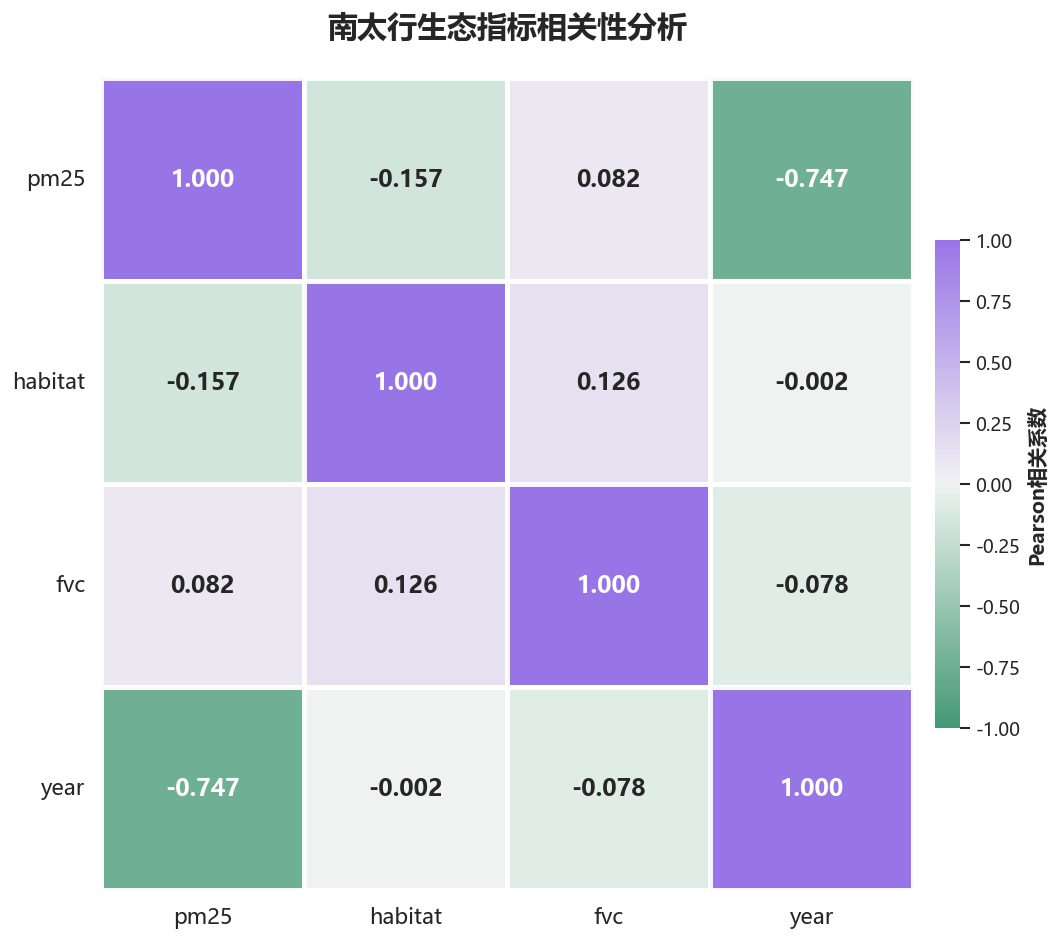

In [9]:
corr = df[["pm25", "habitat", "fvc", "year"]].corr()

plt.figure(figsize=(10, 8), dpi=120)

# 使用美观的配色方案
cmap = sns.diverging_palette(150, 275, s=80, l=55, as_cmap=True)

# 绘制热力图 - 显示所有色块！
heatmap = sns.heatmap(
    corr,
    # mask=mask,  # ← 注释掉这一行，就显示全部色块了
    cmap=cmap,
    annot=True,
    fmt='.3f',
    square=True,
    linewidths=2,
    linecolor='white',
    cbar_kws={
        "shrink": .6, 
        "label": "Pearson相关系数",
        "pad": 0.02
    },
    annot_kws={"size": 14, "weight": "bold"},
    vmin=-1, vmax=1,
    center=0,
    alpha=0.95
)

plt.title('南太行生态指标相关性分析', fontsize=18, fontweight='bold', pad=25)
plt.xticks(fontsize=13, rotation=0, fontweight='500')
plt.yticks(fontsize=13, rotation=0, fontweight='500')

cbar = heatmap.collections[0].colorbar
cbar.set_label('Pearson相关系数', fontsize=12, fontweight='bold')
cbar.ax.tick_params(labelsize=11)

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "图2_相关性热力图.png"), dpi=300, bbox_inches='tight')
plt.show()

8. PCA

In [10]:
X=df[
[
"pm25",
"habitat",
"fvc"
]
]

X_std=StandardScaler().fit_transform(X)

pca=PCA(
    n_components=2
)

pc=pca.fit_transform(
    X_std
)

df["PC1"]=pc[:,0]
df["PC2"]=pc[:,1]


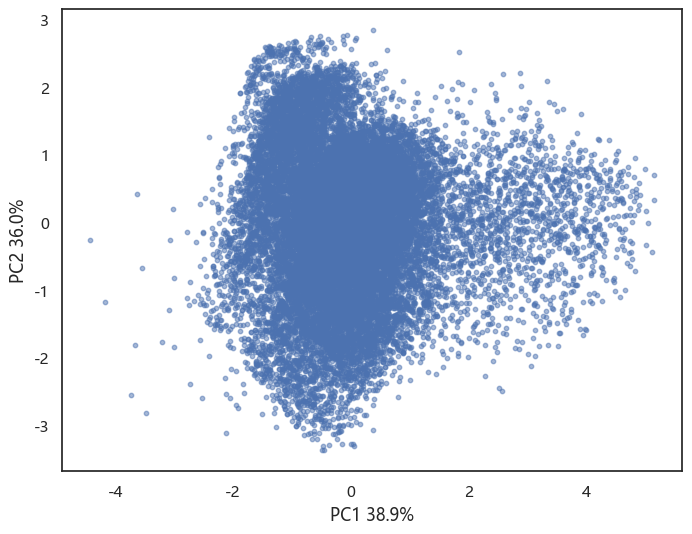

In [11]:
plt.figure(
    figsize=(8,6)
)

plt.scatter(

    df["PC1"],
    df["PC2"],

    s=10,

    alpha=.5

)

plt.xlabel(
    f"PC1 {pca.explained_variance_ratio_[0]*100:.1f}%"
)

plt.ylabel(
    f"PC2 {pca.explained_variance_ratio_[1]*100:.1f}%"
)

plt.savefig(
    os.path.join(
        OUT_DIR,
        "图3_PCA.png"
    ),
    dpi=300
)

9. 图4 自动寻找最佳K

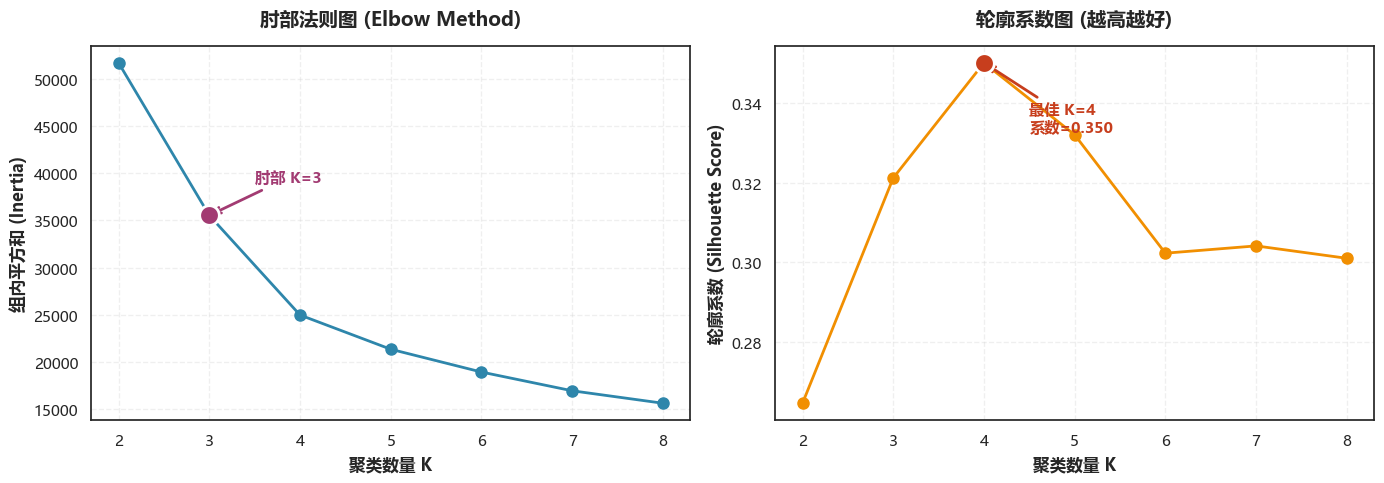

✅ 自动选择最佳聚类数: K = 4
✅ 对应轮廓系数: 0.3502


In [12]:
# ========== 肘部法则 + 轮廓系数 双图展示最佳K ==========
scores = []
inertias = []
k_range = range(2, 9)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_std)
    scores.append(silhouette_score(X_std, labels))
    inertias.append(km.inertia_)

# 创建双栏对比图
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 图1：肘部法则
ax1.plot(k_range, inertias, 'o-', color='#2E86AB', linewidth=2, markersize=8)
ax1.set_xlabel('聚类数量 K', fontsize=12, fontweight='bold')
ax1.set_ylabel('组内平方和 (Inertia)', fontsize=12, fontweight='bold')
ax1.set_title('肘部法则图 (Elbow Method)', fontsize=14, fontweight='bold', pad=15)
ax1.grid(True, alpha=0.3, linestyle='--')
ax1.set_xticks(k_range)

# 标记肘部点
best_k_elbow = 3
ax1.scatter([best_k_elbow], [inertias[best_k_elbow-2]], color='#A23B72', s=200, zorder=5, edgecolor='white', linewidth=2)
ax1.annotate(f'肘部 K={best_k_elbow}', xy=(best_k_elbow, inertias[best_k_elbow-2]), 
             xytext=(best_k_elbow+0.5, inertias[best_k_elbow-2]*1.1),
             arrowprops=dict(arrowstyle='->', color='#A23B72', lw=2),
             fontsize=11, fontweight='bold', color='#A23B72')

# 图2：轮廓系数
ax2.plot(k_range, scores, 'o-', color='#F18F01', linewidth=2, markersize=8)
ax2.set_xlabel('聚类数量 K', fontsize=12, fontweight='bold')
ax2.set_ylabel('轮廓系数 (Silhouette Score)', fontsize=12, fontweight='bold')
ax2.set_title('轮廓系数图 (越高越好)', fontsize=14, fontweight='bold', pad=15)
ax2.grid(True, alpha=0.3, linestyle='--')
ax2.set_xticks(k_range)

# 标记最佳K
best_k = np.argmax(scores) + 2
ax2.scatter([best_k], [np.max(scores)], color='#C73E1D', s=200, zorder=5, edgecolor='white', linewidth=2)
ax2.annotate(f'最佳 K={best_k}\n系数={np.max(scores):.3f}', xy=(best_k, np.max(scores)), 
             xytext=(best_k+0.5, np.max(scores)*0.95),
             arrowprops=dict(arrowstyle='->', color='#C73E1D', lw=2),
             fontsize=11, fontweight='bold', color='#C73E1D')

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "图4_K值寻优对比.png"), dpi=300, bbox_inches='tight')
plt.show()

print(f"✅ 自动选择最佳聚类数: K = {best_k}")
print(f"✅ 对应轮廓系数: {np.max(scores):.4f}")

10. KMeans聚类

In [13]:
best_k = np.argmax(scores) + 2

kmeans = KMeans(
    n_clusters=best_k,
    random_state=42
)

df["cluster"] = kmeans.fit_predict(X_std)

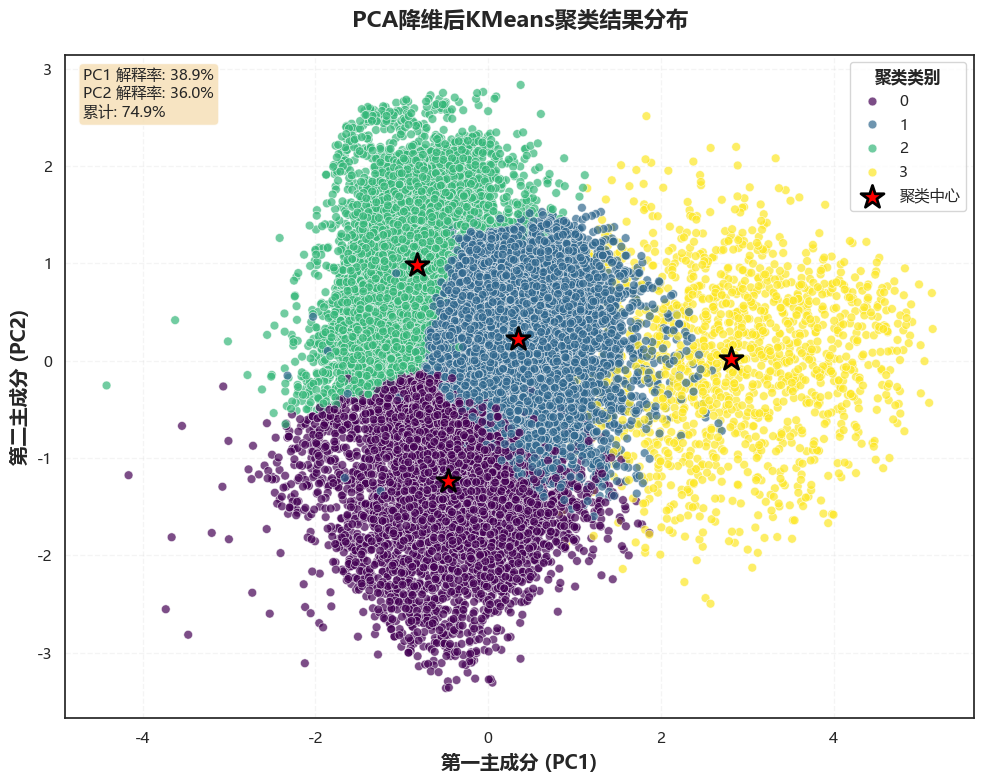

In [14]:
plt.figure(figsize=(10, 8))

# 使用更美观的配色和样式
scatter = sns.scatterplot(
    data=df,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette="viridis",
    s=40,
    alpha=0.7,
    edgecolor='white',
    linewidth=0.5
)

plt.xlabel('第一主成分 (PC1)', fontsize=14, fontweight='bold')
plt.ylabel('第二主成分 (PC2)', fontsize=14, fontweight='bold')
plt.title('PCA降维后KMeans聚类结果分布', fontsize=16, fontweight='bold', pad=20)

# 添加聚类中心
centers = pd.DataFrame(pca.transform(kmeans.cluster_centers_), columns=['PC1', 'PC2'])
plt.scatter(centers['PC1'], centers['PC2'], c='red', s=300, marker='*', 
            edgecolor='black', linewidth=2, zorder=10, label='聚类中心')

plt.legend(title='聚类类别', title_fontproperties={'weight': 'bold'}, fontsize=11)
plt.grid(True, alpha=0.2, linestyle='--')

# 添加方差解释率文本
exp_var = pca.explained_variance_ratio_
plt.text(0.02, 0.98, f'PC1 解释率: {exp_var[0]:.1%}\nPC2 解释率: {exp_var[1]:.1%}\n累计: {exp_var.sum():.1%}',
         transform=plt.gca().transAxes, fontsize=11,
         bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8),
         verticalalignment='top')

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "图5_聚类结果.png"), dpi=300, bbox_inches='tight')
plt.show()

11. 随机森林

In [15]:
X=df[
[
"pm25",
"fvc",
"year"
]
]

y=df["habitat"]

X_train,X_test,y_train,y_test=\
train_test_split(
X,
y,
test_size=.3,
random_state=42
)

rf=RandomForestRegressor(

n_estimators=300,

max_depth=10,

n_jobs=-1,

random_state=42

)

rf.fit(
X_train,
y_train
)

pred=rf.predict(
X_test
)

print(
"R²=",
r2_score(
y_test,
pred
)
)

R²= 0.13357672749543315


SHAP

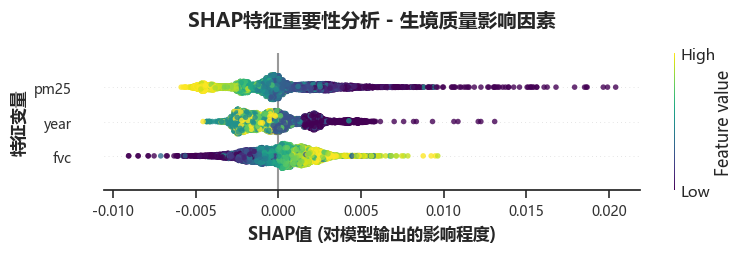


📊 随机森林模型 - 特征重要性排名
  特征    重要性得分
 fvc 0.479224
pm25 0.408620
year 0.112156


In [16]:
explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_test)

plt.figure(figsize=(10, 6))

# 绘制美观的SHAP特征重要性蜜蜂图
shap.summary_plot(
    shap_values, 
    X_test,
    plot_type="dot",
    show=False,
    cmap="viridis",
    alpha=0.8
)

plt.title('SHAP特征重要性分析 - 生境质量影响因素', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('SHAP值 (对模型输出的影响程度)', fontsize=12, fontweight='bold')
plt.ylabel('特征变量', fontsize=12, fontweight='bold')
plt.tick_params(axis='both', labelsize=10)

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "图6_SHAP特征重要性.png"), dpi=300, bbox_inches='tight')
plt.show()

# 打印特征重要性排名
print("\n" + "="*50)
print("📊 随机森林模型 - 特征重要性排名")
print("="*50)
importance = pd.DataFrame({
    '特征': X.columns,
    '重要性得分': rf.feature_importances_
}).sort_values('重要性得分', ascending=False)
print(importance.to_string(index=False))
print("="*50)